In [1]:
from __future__ import print_function
import os
import cv2 
import numpy as np
import pandas as pd   
import matplotlib.pyplot as plt
from PIL import Image
from pillow_heif import register_heif_opener
import random
import xgboost as xgb
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report
from sklearn.model_selection import KFold, cross_val_score, cross_validate
from sklearn.metrics import make_scorer, accuracy_score, precision_score, recall_score, f1_score
from sklearn.model_selection import StratifiedKFold
from skimage.feature import local_binary_pattern
import warnings
import mahotas
warnings.filterwarnings("ignore")

In [2]:
GROUP = "C6"
DTYPE="CMMS"
DIR_TRAIN = "DATA/TRAINING/"
GROUP_path = DIR_TRAIN+GROUP+"/"
# ['10', '11', '12', '13', '14', '15', '16']
HH_path = os.listdir(GROUP_path)
resume = []
data_path = []
for HH in HH_path:
    path_GHH = GROUP_path+HH+"/"
    images = os.listdir(path_GHH)
    path_images = [GROUP_path+HH+"/"+x for x in images]
    data_path.append(path_images)
    resume.append([HH, len(path_images), path_images])
pdDT = pd.DataFrame(resume)    # values
pdDT.columns = ["Humidity", "numberImages", "pathImages"]
pdDT

,Humidity,numberImages,pathImages
0,C6_10,29,"[DATA/TRAINING/C6/C6_10/IMG_7602.HEIC, DATA/TR..."
1,C6_11,29,"[DATA/TRAINING/C6/C6_11/IMG_7781.HEIC, DATA/TR..."
2,C6_12,27,"[DATA/TRAINING/C6/C6_12/IMG_7852.HEIC, DATA/TR..."
3,C6_13,25,"[DATA/TRAINING/C6/C6_13/IMG_7910.HEIC, DATA/TR..."
4,C6_14,27,"[DATA/TRAINING/C6/C6_14/IMG_7972.HEIC, DATA/TR..."
5,C6_15,25,"[DATA/TRAINING/C6/C6_15/IMG_8039_edited.jpg, D..."
6,C6_16,25,"[DATA/TRAINING/C6/C6_16/IMG_810 .HEIC, DATA/TR..."


In [3]:
def read_imgHEIC(pic_path):
    register_heif_opener(); im = Image.open(pic_path)
    return cv2.cvtColor(np.array(im), cv2.COLOR_RGB2BGR)

In [4]:
def flip_image_vertical(image):
    height, width, channels = image.shape
    if(height < width):
        image = cv2.rotate(image, cv2.ROTATE_90_CLOCKWISE)
    return image

In [5]:
def resize_image(img, scale_percent = 10):
     # percent of original size
    width = int(img.shape[1] * scale_percent / 100)
    height = int(img.shape[0] * scale_percent / 100)
    dim = (width, height)
    #print(dim)
    # resize image
    resized = cv2.resize(img, dim, interpolation = cv2.INTER_AREA)
    return resized

Text(0.5, 1.0, '16% IMG_8153.HEIC')

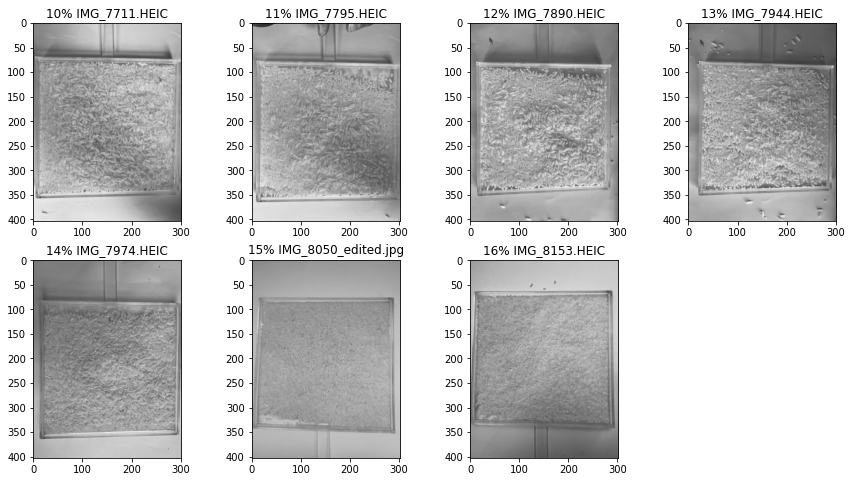

In [10]:
fig=plt.figure(figsize=(15, 8)) 
ax1 = fig.add_subplot(2,4,1); path_image= random.randint(0, 25)
image = read_imgHEIC(data_path[0][path_image]); image = flip_image_vertical(image); image = resize_image(image)
ax1.imshow(image); ax1.set_title("10% " + data_path[0][path_image].split("/")[4])
ax2 = fig.add_subplot(2,4,2); path_image= random.randint(0, 25)
image = read_imgHEIC(data_path[1][path_image]); image = flip_image_vertical(image); image = resize_image(image)
ax2.imshow(image); ax2.set_title("11% "+ data_path[1][path_image].split("/")[4])
ax3 = fig.add_subplot(2,4,3); path_image= random.randint(0, 25)
image = read_imgHEIC(data_path[2][path_image]); image = flip_image_vertical(image); image = resize_image(image)
ax3.imshow(image); ax3.set_title("12% "+ data_path[2][path_image].split("/")[4])
ax4 = fig.add_subplot(2,4,4); path_image= random.randint(0, 25)
image = read_imgHEIC(data_path[3][path_image]); image = flip_image_vertical(image); image = resize_image(image)
ax4.imshow(image); ax4.set_title("13% "+ data_path[3][path_image].split("/")[4])
ax5 = fig.add_subplot(2,4,5); path_image= random.randint(0, 25)
image = read_imgHEIC(data_path[4][path_image]); image = flip_image_vertical(image); image = resize_image(image)
ax5.imshow(image); ax5.set_title("14% "+ data_path[4][path_image].split("/")[4])
ax6 = fig.add_subplot(2,4,6); path_image= random.randint(0, 25)
image = read_imgHEIC(data_path[5][path_image]); image = flip_image_vertical(image); image = resize_image(image)
ax6.imshow(image); ax6.set_title("15% "+ data_path[5][path_image].split("/")[4])
ax7 = fig.add_subplot(2,4,7); path_image= random.randint(0, 25)
image = read_imgHEIC(data_path[6][path_image]); image = flip_image_vertical(image); image = resize_image(image)
ax7.imshow(image); ax7.set_title("16% "+ data_path[6][path_image].split("/")[4])

In [11]:
def color_moments(image):
    # Split the channels - h,s,v
    h, s, v = cv2.split(image)
    # Initialize the color feature
    color_feature = []
    # N = h.shape[0] * h.shape[1]
    
    # The first central moment - average
    h_mean = np.mean(h)  # np.sum(h)/float(N)
    s_mean = np.mean(s)  # np.sum(s)/float(N)
    v_mean = np.mean(v)  # np.sum(v)/float(N)
    color_feature.extend([h_mean, s_mean, v_mean])
    
    # The second central moment - standard deviation
    h_std = np.std(h)  # np.sqrt(np.mean(abs(h - h.mean())**2))
    s_std = np.std(s)  # np.sqrt(np.mean(abs(s - s.mean())**2))
    v_std = np.std(v)  # np.sqrt(np.mean(abs(v - v.mean())**2))
    color_feature.extend([h_std, s_std, v_std])
    
    # The third central moment - the third root of the skewness
    h_skewness = np.mean(abs(h - h.mean())**3)
    s_skewness = np.mean(abs(s - s.mean())**3)
    v_skewness = np.mean(abs(v - v.mean())**3)
    h_thirdMoment = h_skewness**(1./3)
    s_thirdMoment = s_skewness**(1./3)
    v_thirdMoment = v_skewness**(1./3)
    color_feature.extend([h_thirdMoment, s_thirdMoment, v_thirdMoment])
    """
    # The second central moment - standard deviation
    hist_h = cv2.calcHist([h], [0], None, [256], [0, 256])
    hist_h = cv2.normalize(hist_h, hist_h, 0, 1, cv2.NORM_MINMAX)

    hist_s = cv2.calcHist([s], [0], None, [256], [0, 256])
    hist_s = cv2.normalize(hist_s, hist_s, 0, 1, cv2.NORM_MINMAX)

    hist_v = cv2.calcHist([v], [0], None, [256], [0, 256])
    hist_v = cv2.normalize(hist_v, hist_v, 0, 1, cv2.NORM_MINMAX)

    h_skew = kurtosis(hist_h)  
    s_skew = kurtosis(hist_s) 
    v_skew = kurtosis(hist_v) 
    color_feature.extend([h_skew[0], s_skew[0], v_skew[0]])
    
    
    h_kts = kurtosis(hist_h)  
    s_kts = kurtosis(hist_s) 
    v_kts = kurtosis(hist_v) 
    color_feature.extend([h_kts[0], s_kts[0], v_kts[0]])
    
    # The second central moment - standard deviation
    h_ent = entropy(hist_h)  
    s_ent = entropy(hist_s) 
    v_ent = entropy(hist_v) 
    color_feature.extend([h_ent, s_ent, v_ent])
    """
    return color_feature

In [157]:
#Parameters
HH = ['10', '11', '12', '13', '14', '15', '16']
#bins=44; #width=2024; height=3032; 
scale=3
dtHH=[]
for lstImgs, H in zip(data_path, HH):
    arr_img_hist=[]; name_images = []
    for im_path in lstImgs: 
        image = read_imgHEIC(im_path) ; image = flip_image_vertical(image)
        image = resize_image(image, scale)
        #imCrop=centerCrop(image, width, height)
        #print(image.shape)
        [height, width, channels] = image.shape
        nameImage=im_path.split("/")[-1]; name_images.append(nameImage)
        hsv = cv2.cvtColor(image, cv2.COLOR_BGR2HSV)

        features = color_moments(hsv)
        arr_img_hist.append(features)
    pdGrayFeatures = pd.DataFrame(arr_img_hist)
    pdGrayFeatures["scale"] = scale
    pdGrayFeatures["height"] = height
    pdGrayFeatures["width"] = width
    pdGrayFeatures["channels"] = channels
    pdGrayFeatures["IMAGENAME"] = name_images
    pdGrayFeatures["HUMIDITY"] = H
    dtHH.append(pdGrayFeatures)

In [158]:
result = pd.concat(dtHH)

DIR= "FEATURES/ORIGINAL/GLOBAL/TRAINING/"; 
result.to_csv(DIR+'features_s'+str(scale)+'_'+GROUP+'_'+DTYPE+'.csv', index=False)
result.head(10)

,0,1,2,3,4,5,6,7,8,scale,height,width,channels,IMAGENAME,HUMIDITY
0,0.0,0.0,161.584722,0.0,0.0,25.237825,0.0,0.0,28.963082,3,120,90,3,IMG_7602.HEIC,10
1,0.0,0.0,161.359537,0.0,0.0,25.263315,0.0,0.0,28.429558,3,120,90,3,IMG_7605.HEIC,10
2,0.0,0.0,161.314074,0.0,0.0,25.529936,0.0,0.0,28.455302,3,120,90,3,IMG_7607.HEIC,10
3,0.0,0.0,159.780185,0.0,0.0,24.652357,0.0,0.0,28.447824,3,120,90,3,IMG_7610.HEIC,10
4,0.0,0.0,161.176296,0.0,0.0,30.134867,0.0,0.0,34.472333,3,120,90,3,IMG_7613.HEIC,10
5,0.0,0.0,167.695093,0.0,0.0,27.246636,0.0,0.0,30.602144,3,120,90,3,IMG_7619.HEIC,10
6,0.0,0.0,164.595278,0.0,0.0,24.878240,0.0,0.0,28.394212,3,120,90,3,IMG_7621.HEIC,10
7,0.0,0.0,162.148796,0.0,0.0,24.024432,0.0,0.0,27.856496,3,120,90,3,IMG_7625.HEIC,10
8,0.0,0.0,164.181574,0.0,0.0,29.977070,0.0,0.0,34.721567,3,120,90,3,IMG_7695.HEIC,10
9,0.0,0.0,160.985556,0.0,0.0,29.266015,0.0,0.0,34.164377,3,120,90,3,IMG_7697.HEIC,10


# Classification

In [159]:
dtFeatures=result#.drop(['IMAGENAME'], axis=1)
#dtFeatures.head()
X = dtFeatures.values[:, :-6]
#X

In [160]:

# Normalization -> values[0-1]
scaler = MinMaxScaler()
X_scale = scaler.fit_transform(X)     
y = dtFeatures.values[:, -1]
#y

In [161]:
def compute_classification_metrics(y_pred, y_test):
    acc = np.sum(y_pred == y_test) / float(len(y_test))
    precision =np.mean(precision_score(y_test, y_pred, average=None, zero_division=1))
    recall =np.mean(recall_score(y_test, y_pred, average=None, zero_division=1))
    F1 = 2 * (precision * recall) / (precision + recall)
    return acc, precision, recall, F1

In [162]:
def get_CV_CLASSIFICATION_MODELS(model, X, y, rescale=False):
    dt_lg_test=[]  
    if rescale==True:
        y=y-10
        #print(y)
    kfold = StratifiedKFold(n_splits=10, shuffle=True)
    k_fold=1
    for train_index , test_index in kfold.split(X, y):

        X_train , X_test = X[train_index], X[test_index]
        y_train , y_test = y[train_index], y[test_index]
        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)  # predict label

        [acc, precision, recall, F1] = compute_classification_metrics(y_pred, y_test)
        dt_lg_test.append([k_fold, acc, precision, recall, F1])
        k_fold=k_fold+1
    return dt_lg_test

#### Random Forest Classifier

In [163]:
modelRFC=RandomForestClassifier(n_estimators=1000) 
lst_FoldTrain= get_CV_CLASSIFICATION_MODELS(modelRFC, X_scale, y)
modelName="RF_C"

In [164]:
dtFoldTrain = pd.DataFrame(lst_FoldTrain)
dtFoldTrain.columns = ["k_fold", 'accuracy', 'F1', 'precision', 'recall']
dtFoldTrain["DTYPE"]=DTYPE; dtFoldTrain["GROUP"]=GROUP;  dtFoldTrain["MODEL"]=modelName
dtFoldTrain["scale"]=scale; 
dtFoldTrain["height"]=height; dtFoldTrain["width"]=width; dtFoldTrain["channels"]=channels;
dtFoldTrain.to_csv('RESULTS/GLOBAL/CV/'+str(scale)+'/CV_'+GROUP+"_"+DTYPE+'_'+modelName+'.csv', index=False)
dtFoldTrain

,k_fold,accuracy,F1,precision,recall,DTYPE,GROUP,MODEL,scale,height,width,channels
0,1,0.684211,0.726190,0.690476,0.707883,CMMS,C6,RF_C,3,120,90,3
1,2,0.684211,0.695238,0.642857,0.668022,CMMS,C6,RF_C,3,120,90,3
2,3,0.736842,0.814286,0.761905,0.787225,CMMS,C6,RF_C,3,120,90,3
3,4,0.684211,0.747619,0.714286,0.730572,CMMS,C6,RF_C,3,120,90,3
4,5,0.684211,0.714286,0.690476,0.702179,CMMS,C6,RF_C,3,120,90,3
5,6,0.736842,0.752381,0.714286,0.732839,CMMS,C6,RF_C,3,120,90,3
6,7,0.842105,0.857143,0.833333,0.845070,CMMS,C6,RF_C,3,120,90,3
7,8,0.666667,0.785714,0.666667,0.721311,CMMS,C6,RF_C,3,120,90,3
8,9,0.722222,0.738095,0.714286,0.725995,CMMS,C6,RF_C,3,120,90,3
9,10,0.666667,0.630952,0.666667,0.648318,CMMS,C6,RF_C,3,120,90,3


In [165]:
result = dtFoldTrain.groupby(["DTYPE", "GROUP", "MODEL"]).aggregate({'accuracy':'mean','precision':'mean', 
                                                            'recall':'mean', 'F1':'mean'})
result = result.reset_index()
#result.to_csv('RESULTS/GLOBAL/'+TYPE+'/'+GR+'_'+TYPE+'_'+modelName+'_'+str(bins)+'_bins.csv', index=False)
resultRF=result
resultRF

,DTYPE,GROUP,MODEL,accuracy,precision,recall,F1
0,CMMS,C6,RF_C,0.710819,0.709524,0.726942,0.74619


### MLP Classifier

In [166]:
# Import MLPClassifer 
from sklearn.neural_network import MLPClassifier

In [167]:
modelMLPC = MLPClassifier(max_iter=500)
lst_FoldTrain= get_CV_CLASSIFICATION_MODELS(modelMLPC, X_scale, y)
modelName='MLP_C'

In [168]:
dtFoldTrain = pd.DataFrame(lst_FoldTrain)
dtFoldTrain.columns = ["k_fold", 'accuracy', 'F1', 'precision', 'recall']
dtFoldTrain["DTYPE"]=DTYPE; dtFoldTrain["GROUP"]=GROUP;  dtFoldTrain["MODEL"]=modelName
dtFoldTrain["scale"]=scale; 
dtFoldTrain["height"]=height; dtFoldTrain["width"]=width; dtFoldTrain["channels"]=channels;
dtFoldTrain.to_csv('RESULTS/GLOBAL/CV/'+str(scale)+'/CV_'+GROUP+"_"+DTYPE+'_'+modelName+'.csv', index=False)
dtFoldTrain

,k_fold,accuracy,F1,precision,recall,DTYPE,GROUP,MODEL,scale,height,width,channels
0,1,0.578947,0.747619,0.523810,0.616016,CMMS,C6,MLP_C,3,120,90,3
1,2,0.473684,0.513605,0.476190,0.494191,CMMS,C6,MLP_C,3,120,90,3
2,3,0.842105,0.880952,0.857143,0.868885,CMMS,C6,MLP_C,3,120,90,3
3,4,0.684211,0.785714,0.714286,0.748299,CMMS,C6,MLP_C,3,120,90,3
4,5,0.736842,0.797619,0.761905,0.779353,CMMS,C6,MLP_C,3,120,90,3
5,6,0.526316,0.692177,0.547619,0.611470,CMMS,C6,MLP_C,3,120,90,3
6,7,0.684211,0.821429,0.690476,0.750281,CMMS,C6,MLP_C,3,120,90,3
7,8,0.777778,0.750000,0.738095,0.744000,CMMS,C6,MLP_C,3,120,90,3
8,9,0.611111,0.604762,0.595238,0.599962,CMMS,C6,MLP_C,3,120,90,3
9,10,0.666667,0.571429,0.642857,0.605042,CMMS,C6,MLP_C,3,120,90,3


In [169]:
result = dtFoldTrain.groupby(["DTYPE", "GROUP", "MODEL"]).aggregate({'accuracy':'mean','precision':'mean', 
                                                            'recall':'mean', 'F1':'mean'})
result = result.reset_index()#result.to_csv('RESULTS/GLOBAL/'+TYPE+'/'+GR+'_'+TYPE+'_'+modelName+'_'+str(bins)+'_bins.csv', index=False)
resultMLP=result
resultMLP

,DTYPE,GROUP,MODEL,accuracy,precision,recall,F1
0,CMMS,C6,MLP_C,0.658187,0.654762,0.68175,0.716531


### XGBoost Classifier

In [170]:
modelXGBC = xgb.XGBClassifier()
y = np.array([int(x) for x in y])
lst_FoldTrain= get_CV_CLASSIFICATION_MODELS(modelXGBC, X_scale, y, True)
modelName='XGB_C'

In [171]:
dtFoldTrain = pd.DataFrame(lst_FoldTrain)
dtFoldTrain.columns = ["k_fold", 'accuracy', 'F1', 'precision', 'recall']
dtFoldTrain["DTYPE"]=DTYPE; dtFoldTrain["GROUP"]=GROUP;  dtFoldTrain["MODEL"]=modelName
dtFoldTrain["scale"]=scale; 
dtFoldTrain["height"]=height; dtFoldTrain["width"]=width; dtFoldTrain["channels"]=channels;
dtFoldTrain.to_csv('RESULTS/GLOBAL/CV/'+str(scale)+'/CV_'+GROUP+"_"+DTYPE+'_'+modelName+'.csv', index=False)
dtFoldTrain

,k_fold,accuracy,F1,precision,recall,DTYPE,GROUP,MODEL,scale,height,width,channels
0,1,0.684211,0.726190,0.666667,0.695157,CMMS,C6,XGB_C,3,120,90,3
1,2,0.631579,0.742857,0.619048,0.675325,CMMS,C6,XGB_C,3,120,90,3
2,3,0.684211,0.773810,0.666667,0.716253,CMMS,C6,XGB_C,3,120,90,3
3,4,0.842105,0.869048,0.857143,0.863054,CMMS,C6,XGB_C,3,120,90,3
4,5,0.736842,0.830952,0.761905,0.794932,CMMS,C6,XGB_C,3,120,90,3
5,6,0.842105,0.907143,0.809524,0.855558,CMMS,C6,XGB_C,3,120,90,3
6,7,0.631579,0.771429,0.666667,0.715232,CMMS,C6,XGB_C,3,120,90,3
7,8,0.555556,0.671429,0.571429,0.617406,CMMS,C6,XGB_C,3,120,90,3
8,9,0.666667,0.666667,0.642857,0.654545,CMMS,C6,XGB_C,3,120,90,3
9,10,0.833333,0.880952,0.833333,0.856481,CMMS,C6,XGB_C,3,120,90,3


In [172]:
result = dtFoldTrain.groupby(["DTYPE", "GROUP", "MODEL"]).aggregate({'accuracy':'mean','precision':'mean', 
                                                            'recall':'mean', 'F1':'mean'})
result = result.reset_index()#result.to_csv('RESULTS/GLOBAL/'+TYPE+'/'+GR+'_'+TYPE+'_'+modelName+'_'+str(bins)+'_bins.csv', index=False)
resultMLP=result
resultMLP

,DTYPE,GROUP,MODEL,accuracy,precision,recall,F1
0,CMMS,C6,XGB_C,0.710819,0.709524,0.744394,0.784048


# External validation

In [173]:
DIR_TEST = "DATA/TEST/"
GROUP_path = DIR_TEST+GROUP+"/"
# ['10', '11', '12', '13', '14', '15', '16']
HH_path_test = os.listdir(GROUP_path)
resume = []
data_path_test = []
for HH in HH_path_test:
    path_GHH = GROUP_path+HH+"/"
    images = os.listdir(path_GHH)
    path_images = [GROUP_path+HH+"/"+x for x in images]
    data_path_test.append(path_images)
    resume.append([HH, len(path_images), path_images])
pdDT_test = pd.DataFrame(resume)    # values
pdDT_test.columns = ["Humidity", "numberImages", "pathImages"]
pdDT_test

,Humidity,numberImages,pathImages
0,C6_10,5,"[DATA/TEST/C6/C6_10/IMG_7593.HEIC, DATA/TEST/C..."
1,C6_11,5,"[DATA/TEST/C6/C6_11/IMG_7772.HEIC, DATA/TEST/C..."
2,C6_12,5,"[DATA/TEST/C6/C6_12/IMG_7684.HEIC, DATA/TEST/C..."
3,C6_13,5,"[DATA/TEST/C6/C6_13/IMG_7919.HEIC, DATA/TEST/C..."
4,C6_14,5,"[DATA/TEST/C6/C6_14/IMG_7980.HEIC, DATA/TEST/C..."
5,C6_15,5,"[DATA/TEST/C6/C6_15/IMG_8049_edited.jpg, DATA/..."
6,C6_16,5,"[DATA/TEST/C6/C6_16/IMG_8105.HEIC, DATA/TEST/C..."


In [174]:
HH=['10', '11', '12', '13', '14', '15', '16']

In [175]:
dtHH_test=[]
for lstImgs, H in zip(data_path_test, HH):
    arr_img_hist=[]; name_images = []
    for im_path in lstImgs: 
        image = read_imgHEIC(im_path) ; image = flip_image_vertical(image)
        image = resize_image(image, scale)
        #imCrop=centerCrop(image, width, height)
        [height, width, channels] = image.shape
        nameImage=im_path.split("/")[-1]; name_images.append(nameImage)
        hsv = cv2.cvtColor(image, cv2.COLOR_BGR2HSV)
        features = color_moments(hsv)
        arr_img_hist.append(features)
    pdGrayFeatures = pd.DataFrame(arr_img_hist)
    pdGrayFeatures["scale"] = scale
    pdGrayFeatures["height"] = height
    pdGrayFeatures["width"] = width
    pdGrayFeatures["channels"] = channels
    pdGrayFeatures["IMAGENAME"] = name_images
    pdGrayFeatures["HUMIDITY"] = H
    dtHH_test.append(pdGrayFeatures)

In [176]:
result_test = pd.concat(dtHH_test)

DIR= "FEATURES/ORIGINAL/GLOBAL/TESTING/"; 
result_test.to_csv(DIR+'features_s'+str(scale)+'_'+GROUP+'_'+DTYPE+'.csv', index=False)
result_test.head(10)

,0,1,2,3,4,5,6,7,8,scale,height,width,channels,IMAGENAME,HUMIDITY
0,0.0,0.0,158.370556,0.0,0.0,28.160353,0.0,0.0,31.175469,3,120,90,3,IMG_7593.HEIC,10
1,0.0,0.0,163.674167,0.0,0.0,29.857092,0.0,0.0,33.462605,3,120,90,3,IMG_7594.HEIC,10
2,0.0,0.0,159.522222,0.0,0.0,26.280743,0.0,0.0,29.719361,3,120,90,3,IMG_7597.HEIC,10
3,0.0,0.0,160.575741,0.0,0.0,31.179071,0.0,0.0,34.770250,3,120,90,3,IMG_7599.HEIC,10
4,0.0,0.0,159.692222,0.0,0.0,26.163214,0.0,0.0,29.214325,3,120,90,3,IMG_7601.HEIC,10
0,0.0,0.0,160.283519,0.0,0.0,32.693911,0.0,0.0,37.633279,3,120,90,3,IMG_7772.HEIC,11
1,0.0,0.0,161.648333,0.0,0.0,32.369199,0.0,0.0,36.996842,3,120,90,3,IMG_7773.HEIC,11
2,0.0,0.0,162.877685,0.0,0.0,32.333805,0.0,0.0,37.361188,3,120,90,3,IMG_7774.HEIC,11
3,0.0,0.0,161.031944,0.0,0.0,30.121313,0.0,0.0,35.385615,3,120,90,3,IMG_7777.HEIC,11
4,0.0,0.0,161.096204,0.0,0.0,32.344398,0.0,0.0,37.745222,3,120,90,3,IMG_7778.HEIC,11


In [177]:
dtFeaturesTest=result_test#.drop(['IMAGENAME'], axis=1)
#dtFeaturesTest.head()

In [178]:
X_test = dtFeaturesTest.values[:, :-6]
#X_test

In [179]:
X_test_scale = scaler.transform(X_test)     
y_test = dtFeaturesTest.values[:, -1]
y_test

array(['10', '10', '10', '10', '10', '11', '11', '11', '11', '11', '12',
       '12', '12', '12', '12', '13', '13', '13', '13', '13', '14', '14',
       '14', '14', '14', '15', '15', '15', '15', '15', '16', '16', '16',
       '16', '16'], dtype=object)

## RFC

In [180]:
y_pred = modelRFC.predict(X_test_scale)  # predict label

In [181]:
num_classes=7
target_names = ["Class {}".format(i) for i in range(num_classes)]
res = classification_report(y_test, y_pred, target_names=target_names)
print(res)

              precision    recall  f1-score   support

     Class 0       0.25      0.20      0.22         5
     Class 1       0.67      0.80      0.73         5
     Class 2       0.50      0.20      0.29         5
     Class 3       1.00      0.40      0.57         5
     Class 4       0.83      1.00      0.91         5
     Class 5       1.00      1.00      1.00         5
     Class 6       0.40      0.80      0.53         5

    accuracy                           0.63        35
   macro avg       0.66      0.63      0.61        35
weighted avg       0.66      0.63      0.61        35



## MLP

In [182]:
y_pred = modelMLPC.predict(X_test_scale)  # predict label

In [183]:
num_classes=7
target_names = ["Class {}".format(i) for i in range(num_classes)]
res = classification_report(y_test, y_pred, target_names=target_names)
print(res)

              precision    recall  f1-score   support

     Class 0       0.75      0.60      0.67         5
     Class 1       0.62      1.00      0.77         5
     Class 2       0.00      0.00      0.00         5
     Class 3       1.00      0.80      0.89         5
     Class 4       0.83      1.00      0.91         5
     Class 5       1.00      1.00      1.00         5
     Class 6       0.40      0.40      0.40         5

    accuracy                           0.69        35
   macro avg       0.66      0.69      0.66        35
weighted avg       0.66      0.69      0.66        35



## XGBC

In [184]:
y_pred = modelXGBC.predict(X_test_scale) 

In [185]:
num_classes=7
target_names = ["Class {}".format(i) for i in range(num_classes)]
y_test = np.array([int(x) for x in y_test])
res = classification_report(y_test-10, y_pred, target_names=target_names)
print(res)

              precision    recall  f1-score   support

     Class 0       0.00      0.00      0.00         5
     Class 1       0.67      0.80      0.73         5
     Class 2       0.33      0.20      0.25         5
     Class 3       0.75      0.60      0.67         5
     Class 4       1.00      1.00      1.00         5
     Class 5       0.83      1.00      0.91         5
     Class 6       0.38      0.60      0.46         5

    accuracy                           0.60        35
   macro avg       0.57      0.60      0.57        35
weighted avg       0.57      0.60      0.57        35

